# DC Motor Speed Control: Single Loop versus Cascade with Current Limit

`06_dc_motor_speed` | level 2 | experiment id(s): `exp_06_dc_motor_speed_control`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 3 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Derive the speed/voltage transfer function of a brushed DC motor and verify a simulation against
  the exact step response and the exact steady-state formula.
- Design a cascade controller (inner current PI, outer speed PI) and a single-loop speed PI for the
  same speed bandwidth, and compare peak armature current, overshoot, settling time, load
  rejection and speed ripple under encoder quantisation.
- State what happens to each design when inertia triples or the winding resistance rises by 30%.

## 2. Real-World Engineering Problem

A DC motor driven by a 24 V supply with a 2 ohm winding can draw 12 A at standstill. A single-loop
speed controller that puts a voltage on the winding for a speed step produces a current set only by
its gain, which a drive's current limit would not allow. Industrial drives therefore use a
current loop inside the speed loop, which limits torque directly. This notebook measures how large
the difference is for one set of illustrative motor parameters.

## 3. Research Background

The DC motor model and its transfer functions are textbook material (Krause et al., 2013).
Cascade control, with the inner loop faster than the outer, is covered in process-control texts
(Seborg et al., 2016); anti-windup for saturating loops in Astrom and Hagglund (1995). Section 4
lists what was verified.

## 4. Research Literature

The three books are cited for method. No numerical result from them is used; the motor parameters are
illustrative and are not from any datasheet.

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| krause2013 | Krause, P. C.; Wasynczuk, O.; Sudhoff, S. D.; Pekarek, S. D. (2013). Analysis of Electric Machinery and Drive Systems, 3rd ed.. Wiley-IEEE Press. ISBN 978-1-118-02429-4. | Reference-frame theory, PMSM and BLDC models, averaged converter models. | Textbook; parameters for a specific machine must come from its datasheet. | verified (2026-11-25, web search of publisher/index/library record). Publisher-affiliated page and a retailer record agree on edition, year and ISBN. |
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |
| seborg2016 | Seborg, D. E.; Edgar, T. F.; Mellichamp, D. A.; Doyle, F. J. (2016). Process Dynamics and Control, 4th ed.. Wiley. ISBN 978-1-119-28591-5. | Process-control textbook: FOPDT models, reaction-curve methods, tuning rules. | Which tuning rules and identification methods it covers was not checked page by page in this build. | verified (2026-11-25, web search of publisher/index/library record). Publisher listing gives edition, year and ISBN. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

Armature circuit and shaft ($L$ H, $R$ ohm, $K_t=K_e$ for an ideal motor, $J$, $B$, load torque $T_l$):
$$L\dot i=v-Ri-K_e\omega,\qquad J\dot\omega=K_ti-B\omega-T_l.$$

Speed/voltage transfer function (zero load torque):
$$\frac{\Omega(s)}{V(s)}=\frac{K_t}{JLs^2+(JR+BL)s+(RB+K_tK_e)}.$$
DC gain $K_t/(RB+K_tK_e)$. **Steady state under load:**
$\omega_{ss}=(K_tv-RT_l)/(RB+K_tK_e)$ and $i_{ss}=(T_l+B\omega)/K_t$.

**Current loop.** With plant $1/(Ls+R)$ and PI $k_p(1+1/(T_is))$, choosing $T_i=L/R$ cancels the pole,
leaving $1/(\tau s+1)$ with $\tau=1/\omega_c$ when $k_p=L\omega_c$, $k_i=R\omega_c$. The 10% to 90% rise
time of that response is $2.197/\omega_c$. Back-EMF is treated as a disturbance.

**Speed loop** (current loop assumed ideal): plant $K_t/(Js)$, PI with
$k_p=2J\omega_n/K_t$, $k_i=J\omega_n^2/K_t$ (double pole at $\omega_n$). Friction and current-loop lag are
neglected, so the result is a starting point.

**Single-loop PI** (lambda tuning on the first-order approximation $K/(\tau_m s+1)$, $\tau_m=JR/(K_tK_e+RB)$):
$k_p=\tau_m/(K\lambda)$, $T_i=\tau_m$, $\lambda=1/\omega_n$. This ignores the electrical pole.

## 6. System Modeling

Illustrative 24 V gear-motor class parameters (library defaults): `R = 2.0 ohm`, `L = 3 mH`,
`Kt = Ke = 0.08`, `J = 4e-5 kg m^2`, `B = 2e-5`, no Coulomb friction. Time constants: `tau_mech = 12.4 ms`,
`tau_elec = 1.5 ms`. Simulation step 0.2 ms (RK4, 4 substeps); the speed loop runs every 5th step (1 ms).
Reference 120 rad/s from rest, load torque step of 0.05 N m at 0.5 s. Current limit 3 A
(25% of the 12 A stall current). Parameter variants: inertia x3, resistance x1.3 (hot winding),
`Kt`, `Ke` x0.9 (weaker magnets). The controllers always keep the nominal design values.

## 7. Dataset and Measurement Data

No dataset; the motor is simulated. The encoder is represented by a speed quantisation step of
1.57 rad/s (2 pi / 4000 counts per 1 ms window), applied to the measured speed only.

## 8. Algorithm Architecture

Three controllers with the same speed bandwidth (`wn = 2 pi * 20 Hz`):
**A** single-loop PI, output = armature voltage (limit +-24 V, back-calculation anti-windup);
**B** cascade, inner current PI at 150 Hz, outer speed PI, current reference limited to +-3 A;
**C** same as B plus back-EMF feed-forward `Ke * speed` on the voltage.

## 9. Algorithm Implementation

In [2]:
from control_lab.controllers import PID, CascadeSpeedController
from control_lab.controllers.foc import speed_loop_gains
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.metrics import iae, ripple_peak_to_peak_percent, step_response_metrics
from control_lab.motors import DCMotor, DCMotorParams
from control_lab.simulation import run_closed_loop
from scipy import signal

EXP = "exp_06_dc_motor_speed_control"
P0 = DCMotorParams()
Ts, RATIO, I_MAX, F_SPEED, F_CUR = 2e-4, 5, 3.0, 20.0, 150.0
R_REF, T_LOAD, T_LOAD_AT, T_END = 120.0, 0.05, 0.5, 1.0
QUANT = 2 * np.pi / 4000 / 1e-3

def make_motor(p=P0):
    return DCMotor(p, Ts=Ts, substeps=4)

def design(p=P0):
    wn = 2 * np.pi * F_SPEED
    kp_w, ki_w = speed_loop_gains(p.J, p.Kt, F_SPEED)
    wc = 2 * np.pi * F_CUR
    cur = dict(kp=p.L * wc, ki=p.R * wc)
    K, tm = p.dc_gain, p.tau_mech
    lam = 1.0 / wn
    single = {"kp": tm / (K * lam), "ti": tm}    # lambda tuning, L = 0 (first-order model)
    return dict(kp_w=kp_w, ki_w=ki_w, cur=cur, single=single)

def make_controller(kind, motor, D):
    if kind == "A single-loop PI":
        s = D["single"]
        return PID.from_times(s["kp"], s["ti"], 0.0, Ts=Ts, u_min=-P0.v_max, u_max=P0.v_max, antiwindup="backcalc")
    speed = PID(D["kp_w"], D["ki_w"], Ts=RATIO * Ts, u_min=-I_MAX, u_max=I_MAX, antiwindup="backcalc")
    cur = PID(D["cur"]["kp"], D["cur"]["ki"], Ts=Ts, u_min=-P0.v_max, u_max=P0.v_max, antiwindup="backcalc")
    return CascadeSpeedController(motor, speed, cur, RATIO, ke=P0.Ke, bemf_ff=(kind == "C cascade + back-EMF ff"))

def run(kind, p=P0, quant=0.0, t_end=T_END):
    motor = make_motor(p)
    D = design(P0)    # design values come from the NOMINAL motor
    ctl = make_controller(kind, motor, D)
    n = int(round(t_end / Ts)); t = np.arange(n) * Ts
    o = run_closed_loop(motor, ctl, np.full(n, R_REF), Ts, disturbance=np.where(t >= T_LOAD_AT, T_LOAD, 0.0),
                        quant_step=quant, record={"i": lambda m: m.current})
    return o

`design` always uses the nominal motor so that the variants test robustness to parameter error, not
re-tuning. The inner loop sees `motor.current` directly, as a drive with a current sensor does.

## 10. Simulation and Numerical Analysis

Sections 11 and 12 run: model verification (open loop), current-loop verification (rotor effectively
locked), the controller comparison on the nominal motor, and the three parameter variants.

## 11. Experimental Validation

Level: **software simulation**. Independent references: `scipy.signal.step` on the analytic transfer
function, the closed-form steady-state speed and current, and the closed-form current-loop rise time.
These test the motor model and the tuning formulas. The controller comparison is a simulation result
only; no real motor, drive or encoder was used.

## 12. Performance Evaluation

In [3]:
checks = []
# 1. open-loop step against the exact transfer function
n = int(0.12 / Ts); t = np.arange(n) * Ts
m = make_motor(); v = 12.0
w_sim = np.array([m.y] + [m.step(v, 0.0) for _ in range(n - 1)])      # y[k] at start of sample k
num, den = P0.transfer_function_coeffs()
_, w_ex = signal.step(signal.TransferFunction(np.array(num) * v, den), T=t)
err = np.max(np.abs(w_sim - w_ex)) / w_ex[-1]
checks.append(check("open-loop step matches scipy exact step (max error / final)", err < 2e-3, f"{err:.2e}"))
# 2. steady state with load
m = make_motor()
for _ in range(int(0.3 / Ts)): m.step(12.0, 0.05)
w_th = (P0.Kt * 12.0 - P0.R * 0.05) / (P0.R * P0.B + P0.Kt * P0.Ke)
i_th = (0.05 + P0.B * w_th) / P0.Kt
checks.append(check("steady-state speed equals (Kt v - R Tl)/(RB + Kt Ke)", abs(m.y - w_th) / w_th < 1e-3, f"{m.y:.3f} vs {w_th:.3f}"))
checks.append(check("steady-state current equals (Tl + B w)/Kt", abs(m.current - i_th) / i_th < 1e-3, f"{m.current:.4f} vs {i_th:.4f}"))
# 3. poles of the transfer function equal the eigenvalues of the state matrix
A = np.array([[-P0.R / P0.L, -P0.Ke / P0.L], [P0.Kt / P0.J, -P0.B / P0.J]])
pa, pb = np.sort(np.linalg.eigvals(A).real), np.sort(np.roots(den).real)
checks.append(check("TF poles equal state-matrix eigenvalues", np.allclose(pa, pb, rtol=1e-8), f"{pb}"))

# 4. current loop rise time with the rotor effectively locked (J x 1000)
class CurrentPlant:
    def __init__(self, motor): self.m = motor
    @property
    def y(self): return self.m.current
    def reset(self): self.m.reset()
    def step(self, u, d=0.0): return self.m.step(u, 0.0)
mm = make_motor(P0.with_changes(J=P0.J * 1000)); D0 = design()
ci = PID(D0["cur"]["kp"], D0["cur"]["ki"], Ts=Ts, u_min=-24, u_max=24, antiwindup="backcalc")
oc = run_closed_loop(CurrentPlant(mm), ci, np.full(int(0.02 / Ts), 1.0), Ts)
tt, yy = oc["t"], oc["y"]
t10, t90 = tt[np.argmax(yy >= 0.1)], tt[np.argmax(yy >= 0.9)]
rise, rise_th = t90 - t10, 2.197 / (2 * np.pi * F_CUR)
checks.append(check("current-loop 10-90% rise time within 20% of 2.197/wc", abs(rise - rise_th) / rise_th < 0.20, f"{rise*1e3:.2f} ms vs {rise_th*1e3:.2f} ms"))
metrics_cur = {"rise_time_ms": rise * 1e3, "rise_time_theory_ms": rise_th * 1e3}

# 5. controller comparison on nominal and variants
KINDS = ["A single-loop PI", "B cascade", "C cascade + back-EMF ff"]
VARIANTS = {"nominal": P0, "inertia x3": P0.with_changes(J=3 * P0.J), "R x1.3": P0.with_changes(R=1.3 * P0.R),
            "Kt, Ke x0.9": P0.with_changes(Kt=0.9 * P0.Kt, Ke=0.9 * P0.Ke)}
rows, store = [], {}
for vn, pv in VARIANTS.items():
    for kind in KINDS:
        o = run(kind, pv); store[(vn, kind)] = o
        i_a = int(T_LOAD_AT / Ts)
        sp = step_response_metrics(o["t"][:i_a], o["y"][:i_a], R_REF)
        yl = o["y"][i_a:]
        dip = R_REF - yl.min()
        band = np.flatnonzero(np.abs(yl - R_REF) > 0.02 * R_REF)
        rec = (band[-1] + 1) * Ts if band.size else 0.0
        rows.append(dict(variant=vn, controller=kind, peak_current_A=float(np.max(np.abs(o["i"]))),
                         overshoot_percent=sp["overshoot_percent"], settling_time_ms=sp["settling_time"] * 1e3,
                         iae_setpoint=iae(o["t"][:i_a], o["e"][:i_a]), load_dip_rad_s=float(dip),
                         load_recovery_ms=rec * 1e3, ess_before_load_percent=100 * abs(R_REF - o["y"][i_a - 1]) / R_REF,
                         ess_end_percent=100 * abs(R_REF - o["y"][-1]) / R_REF,
                         peak_voltage_V=float(np.max(np.abs(o["u"])))))
import pandas as pd
df = pd.DataFrame(rows)
print(df.round(3).to_string(index=False))
nom = df[df.variant == "nominal"].set_index("controller")
checks.append(check("single loop draws more than 2x the current limit on the speed step", nom.loc[KINDS[0], "peak_current_A"] > 2 * I_MAX, f"{nom.loc[KINDS[0], 'peak_current_A']:.2f} A vs limit {I_MAX} A"))
for k in KINDS[1:]:
    checks.append(check(f"{k}: current stays within 10% of the limit (nominal)", nom.loc[k, "peak_current_A"] < 1.10 * I_MAX, f"{nom.loc[k, 'peak_current_A']:.2f} A"))
for k in KINDS:
    checks.append(check(f"{k}: zero steady-state error before and after load (nominal)", nom.loc[k, "ess_before_load_percent"] < 0.5 and nom.loc[k, "ess_end_percent"] < 0.5, f"{nom.loc[k, 'ess_before_load_percent']:.3f} %, {nom.loc[k, 'ess_end_percent']:.3f} %"))
o = store[("nominal", "B cascade")]
i_end = o["i"][-int(0.05 / Ts):].mean(); i_th2 = (T_LOAD + P0.B * R_REF) / P0.Kt
checks.append(check("cascade steady current equals (Tl + B w)/Kt", abs(i_end - i_th2) / i_th2 < 0.02, f"{i_end:.4f} vs {i_th2:.4f} A"))
# 6. quantisation ripple
rip = {}
for k in KINDS:
    oq = run(k, quant=QUANT); a, b = int(0.3 / Ts), int(0.5 / Ts)
    rip[k] = {"true_speed_ripple_pp_percent": ripple_peak_to_peak_percent(oq["y"][a:b]), "current_ripple_pp_A": float(np.ptp(oq["i"][a:b]))}
print(pd.DataFrame(rip).T.round(3))
for c_ in checks:
    if not c_["passed"]: print("FAIL", c_["name"], c_["detail"])
print(sum(c["passed"] for c in checks), "of", len(checks), "checks passed")

    variant              controller  peak_current_A  overshoot_percent  settling_time_ms  iae_setpoint  load_dip_rad_s  load_recovery_ms  ess_before_load_percent  ess_end_percent  peak_voltage_V
    nominal        A single-loop PI           6.362              0.000              32.6         0.943           5.225              23.6                      0.0              0.0          16.020
    nominal               B cascade           2.776             10.722              52.0         1.644           4.133              16.4                      0.0              0.0          14.845
    nominal C cascade + back-EMF ff           3.000             11.088              49.2         1.555           4.308              16.0                      0.0              0.0          15.047
 inertia x3        A single-loop PI           8.313             16.647              83.6         2.373           3.873              37.2                      0.0              0.0          19.489
 inertia x3              

                         true_speed_ripple_pp_percent  current_ripple_pp_A
A single-loop PI                                0.043                0.053
B cascade                                       0.351                0.184
C cascade + back-EMF ff                         0.398                0.222
12 of 12 checks passed


The checks separate three questions: is the motor model right (checks 1-3), is the tuning formula
right (current-loop rise time), and does the controller behave as claimed (current limit, zero error).
The table is the comparison; read it with the variants, not only the nominal rows.

## 13. Visualization and Interpretation

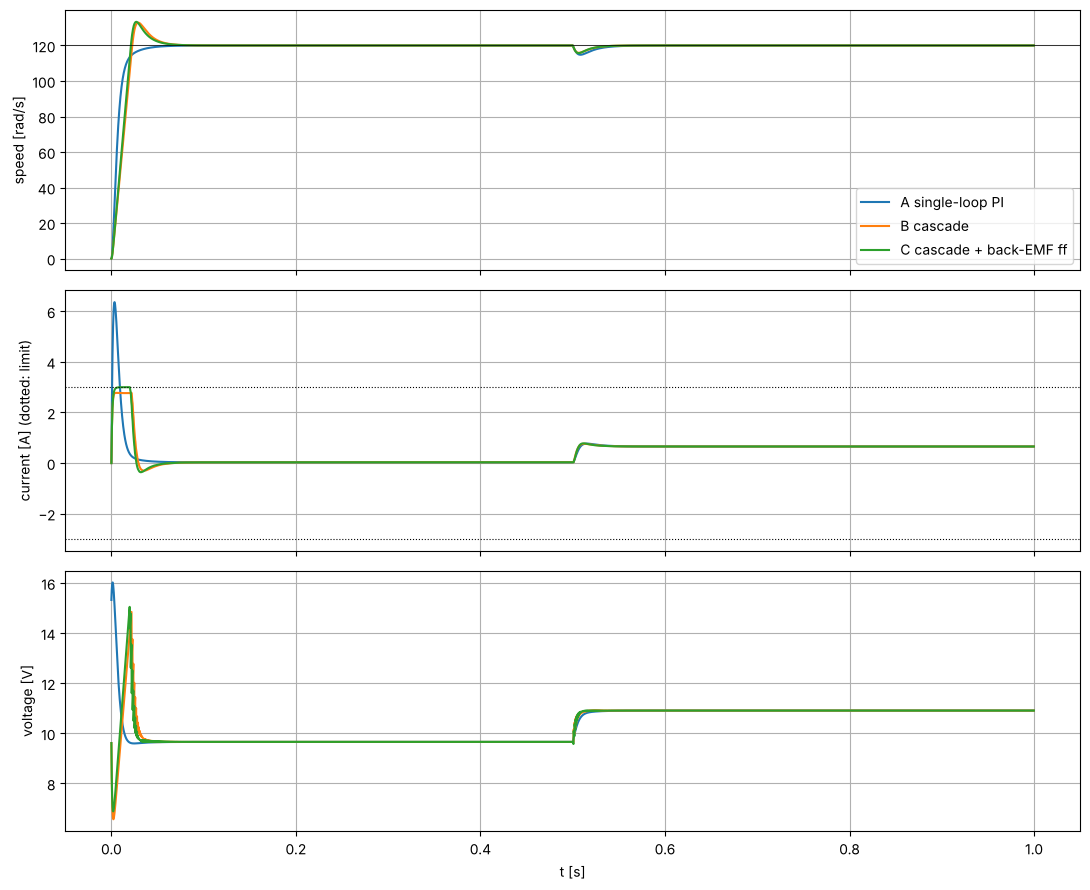

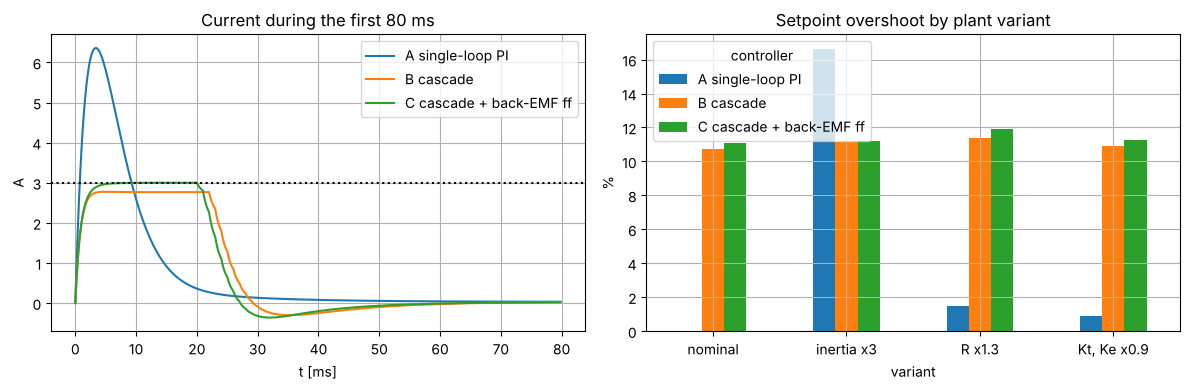

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for kind in KINDS:
    o = store[("nominal", kind)]
    ax[0].plot(o["t"], o["y"], label=kind); ax[1].plot(o["t"], o["i"]); ax[2].plot(o["t"], o["u"])
ax[0].axhline(R_REF, color="k", lw=0.5); ax[1].axhline(I_MAX, color="k", ls=":", lw=0.8); ax[1].axhline(-I_MAX, color="k", ls=":", lw=0.8)
ax[0].set(ylabel="speed [rad/s]"); ax[1].set(ylabel="current [A] (dotted: limit)"); ax[2].set(ylabel="voltage [V]", xlabel="t [s]")
ax[0].legend(); fig.tight_layout()
figs = [save_figure(fig, EXP, "nominal_step_and_load")]
plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for kind in KINDS:
    o = store[("nominal", kind)]; k0 = int(0.0 / Ts); k1 = int(0.08 / Ts)
    ax[0].plot(o["t"][k0:k1] * 1e3, o["i"][k0:k1], label=kind)
ax[0].axhline(I_MAX, color="k", ls=":"); ax[0].set(title="Current during the first 80 ms", xlabel="t [ms]", ylabel="A"); ax[0].legend()
piv = df.pivot(index="variant", columns="controller", values="overshoot_percent").loc[list(VARIANTS)]
piv.plot.bar(ax=ax[1], rot=0); ax[1].set(title="Setpoint overshoot by plant variant", ylabel="%")
fig.tight_layout()
figs.append(save_figure(fig, EXP, "startup_current_and_variants"))
plt.show()

The first figure shows the trade: the cascade holds the current near its limit and reaches the speed
later, while the single loop reaches it sooner with a larger current peak (set by its own gain here,
not by the 24 V supply, which is not reached).

## 14. Research Discussion and Limitations

**Observed in this run (nominal motor unless stated; table in section 12).**
- All three designs reach zero steady-state error before and after the load step.
- **Peak current.** Single loop: 6.4 A (53% of the 12 A stall current), set by its own gain
  (peak voltage 16.0 V, of which the proportional term is 15.1 V, across 2 ohm), not by any limit. Cascade: 2.8 A, and 3.0 A with
  back-EMF feed-forward (touching the 3 A limit). With inertia x3 the single loop rises to 8.3 A;
  the cascade stays at 2.9 to 3.0 A.
- **Speed of response, the price of the limit.** Single loop settles in 32.6 ms with 0% overshoot;
  the cascade settles in 52 ms with about 11% overshoot (current-limited acceleration, and the PI zero).
  With inertia x3 the single loop overshoots 16.7% and the cascade 11.1%.
- **Back-EMF feed-forward** changes little: IAE 1.56 against 1.64, same load recovery (16 ms),
  slightly higher overshoot (11.1% against 10.7%).
- **Encoder quantisation.** The single loop's speed ripple is 0.04% peak to peak; the cascade's is
  0.35% (0.40% with feed-forward), and its current ripple is 0.18 A against 0.05 A, because quantisation
  noise passes through the speed controller's proportional gain into the current reference.

**Inference (not tested here).** The ranking would change if the single loop were tuned more
aggressively (higher current) or the cascade given a setpoint filter or `b < 1` (less overshoot);
the comparison is for one tuning of each.

**Limits.** (1) All parameters are illustrative, not from a datasheet or identified. (2) The current
is read exactly; a real current sensor adds offset, noise and a sampling delay related to the PWM
cycle, and the 0.2 ms loop here is a modelling choice rather than a switching-converter model (no
inverter, no dead time, no PWM ripple). (3) The 24 V supply is ideal; a real supply sags at current
peaks. (4) Encoder quantisation is a fixed speed-resolution step, not a count-based estimator with
its own delay. (5) The current limit is a software limit; a hardware overcurrent trip is still
required. (6) Parameter variants change one parameter at a time; combined drift was not tested.
(7) Friction is purely viscous. (8) The "2x the limit" threshold in the checks is my choice and the
margin is thin (6.36 A against 6.0 A).

## 15. Summary, Exercises, and Further Research

**Key insights.** A speed loop that commands voltage cannot limit current; a current loop inside it
can, at the cost of an extra loop to tune and a current sensor.

**Exercises.** (1) Raise the speed bandwidth to 40 Hz and find where the cascade overshoots.
(2) Add Coulomb friction `Tc = 0.005` and check the steady-state error with the PI. (3) Replace the
speed quantiser with a 1 kHz count-difference estimator and compare ripple. (4) Add a 24 V supply
with 0.2 ohm internal resistance to the single-loop design.

**Related.** PID (03), tuning (04), BLDC six-step (09), PMSM FOC (10), conveyor (11).
**Research directions.** Sensorless speed estimation and torque-ripple compensation.

In [5]:
rec_ = ExperimentRecord(
    experiment_id=EXP, title="DC motor speed control: single loop vs cascade with current limit",
    notebook="notebooks/04_motor_control/06_dc_motor_speed.ipynb",
    algorithm="Cascade PI (current inner, speed outer) vs single-loop PI",
    application="Brushed DC gear motor, illustrative", plant_model="2nd-order DC motor (RK4)",
    dataset={"name": "none", "kind": "simulated", "description": "Simulated motor with illustrative parameters."},
    metrics={"current_loop": metrics_cur, "table": rows, "quantisation_ripple": rip},
    checks=checks, sampling_time_s=Ts, random_seed=None, number_of_trials=len(rows),
    controller_parameters={"speed_bandwidth_hz": F_SPEED, "current_bandwidth_hz": F_CUR, "current_limit_A": I_MAX, "speed_loop_ratio": RATIO},
    plant_parameters=P0.as_dict(), input_configuration={"speed_step_rad_s": R_REF},
    disturbance_configuration={"load_step_Nm": T_LOAD, "at_s": T_LOAD_AT},
    operating_conditions={"supply_V": P0.v_max, "encoder_quantisation_rad_s": QUANT, "variants": list(VARIANTS)},
    figure_references=figs,
    limitations=["Illustrative motor parameters, not identified.", "No inverter, PWM, dead time or supply sag.",
                 "Ideal current sensor; quantisation modelled as a fixed speed step.",
                 "Parameter variants one at a time.", "No hardware validation."])
print(rec_.save())

experiments/results/exp_06_dc_motor_speed_control.json
